# 4376 A line: res2d x res3d sweep, 200G facula on a continuum-only SSD photosphere

Based on `Actress_4376_continuum_SSD.ipynb`, at a single geometry: lat -30, long 0, r 15 deg, v_eq 4000 m/s, i = 0.

At i = 0 the facula stays at the same mu for the whole rotation, so the disk-integrated contrast should be the same at every phase. Any spread between phases comes from the grid: the 3D healpix grid (res3d) and the 2D projected image (res2d). This notebook measures that spread at the line core over a res2d x res3d grid, to find the resolution that makes it closest to 0.

Extent = max - min over rotation phases of the contrast in one fixed wavelength bin: the deepest bin of the phase-0 contrast curve in the plot window.

Run from `actress_highres/actress/` (all paths are relative to it).

In [1]:
import os
import sys
import multiprocessing as mp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

In [2]:
# ----- limb-darkening inputs, cut to the wavelengths the line window needs -----
# Starts from the power2 fits written by Actress_4376_continuum_SSD.ipynb (cell "limb-darkening fits over
# the 4376 line window") rather than refitting, so those files are not rewritten here.
full_hd_ld_file = 'test_phot_continuum_4376.txt'
full_fac_ld_file = 'test_fac_200G_4376.txt'

for ld_file in (full_hd_ld_file, full_fac_ld_file):
    if not os.path.exists(ld_file):
        raise FileNotFoundError(f"{ld_file} not found; run the limb-darkening cell of Actress_4376_continuum_SSD.ipynb first")

full_hd_ld = np.loadtxt(full_hd_ld_file)
full_fac_ld = np.loadtxt(full_fac_ld_file)
if not np.array_equal(full_hd_ld[:, 0], full_fac_ld[:, 0]):
    raise ValueError(f"Wavelength grids of {full_hd_ld_file} and {full_fac_ld_file} differ")

# Same plot window as Actress_4376_continuum_SSD.ipynb.
plot_wav_lower = 4377.0    # Angstrom
plot_wav_higher = 4377.35  # Angstrom

# At i = 0 every Doppler shift is exactly 0 (checked on the existing i0 res6 run), so each output bin
# holds only its own input wavelength. The window then needs, on each side, 2 wavelengths beyond it:
# one so the bins cover the window edge (plot_window_mask requires it), and one that
# process_disk_directory always trims (the outermost bin's half-width edge lies outside the input range).
# This margin is NOT enough at i != 0, where the trim grows with the maximum shift; the simulation cell raises then.
n_margin = 2
full_wavelengths_angstroms = full_hd_ld[:, 0] * 1e10   # file wavelengths are in m
inside = np.where((full_wavelengths_angstroms >= plot_wav_lower) & (full_wavelengths_angstroms <= plot_wav_higher))[0]
first_row = inside[0] - n_margin
last_row = inside[-1] + n_margin
if first_row < 0 or last_row > len(full_hd_ld) - 1:
    raise ValueError(f"Fitted wavelengths {full_wavelengths_angstroms[0]:.4f}-{full_wavelengths_angstroms[-1]:.4f} A "
                     f"do not extend {n_margin} samples beyond the window {plot_wav_lower}-{plot_wav_higher} A")
hd_ld = full_hd_ld[first_row:last_row + 1]
fac_ld = full_fac_ld[first_row:last_row + 1]

wav_lower_angstroms = hd_ld[0, 0] * 1e10
wav_higher_angstroms = hd_ld[-1, 0] * 1e10
subset_tag = f"{wav_lower_angstroms:.4f}_{wav_higher_angstroms:.4f}"
hd_ld_file = f'test_phot_continuum_4376_{subset_tag}.txt'
fac_ld_file = f'test_fac_200G_4376_{subset_tag}.txt'

# Never silently overwrite: if a subset file already exists it must match the rows cut here.
for subset_file, subset_rows in ((hd_ld_file, hd_ld), (fac_ld_file, fac_ld)):
    if os.path.exists(subset_file):
        if not np.allclose(np.loadtxt(subset_file), subset_rows, rtol=1e-12, atol=0):
            raise ValueError(f"{subset_file} exists but differs from the rows cut here. "
                             "Delete or rename it by hand if it should be replaced.")
        print(f"Using existing {subset_file} (identical to the one cut here)")
    else:
        np.savetxt(subset_file, subset_rows)
        print(f"Wrote {subset_file}")

print(f"{len(hd_ld)} of {len(full_hd_ld)} wavelengths, {wav_lower_angstroms:.4f}-{wav_higher_angstroms:.4f} A")


Wrote test_phot_continuum_4376_4376.9661_4377.3688.txt
Wrote test_fac_200G_4376_4376.9661_4377.3688.txt
24 of 57 wavelengths, 4376.9661-4377.3688 A


In [3]:
# ----- simulations over the res2d x res3d grid -----
def run_disk_simulation(hd_ld_file, fac_ld_file, fac_r, fac_long, fac_lat, v_eq, inc, n_phases, res2d, res3d, save):
    # Runs in a separate process so actress loads fresh, as in Actress_4376_continuum_SSD.ipynb.
    import actress.run_actress_notebook as actr

    params = actr.Transitparams()

    # star parameters
    params.res3d = res3d        # resolution of the 3d healpix grid 2^n
    params.res2d = res2d        # Resolution of the resulting 2d simulation box (one side)
    params.v_eq = v_eq          # Equatorial rotational velocity in m/s
    params.inc = inc            # Inclination of the star's rotation axis in degrees
    params.N = n_phases         # Number of phases
    params.mode = 'faconly'
    params.fac_r    = [fac_r]   # degrees
    params.fac_long = [fac_long]
    params.fac_lat  = [fac_lat]
    params.fac_band = False
    params.fac_band_low = [0]
    params.fac_band_high = [0]
    params.ld = 'power2'

    # planet parameters (unused by disk_save, but Transitsim requires them)
    params.rp = 0.1808
    params.b = -0.04
    params.a = 2
    params.T = 20
    params.phi = .5

    print(f"Starting execution for: {save}")
    actr.Transitsim(params).sim_spectrum(hd_ld_file=hd_ld_file, fac_ld_file=fac_ld_file, gif_save=None, lightcurve_save=None, disk_save=save)


fac_r = 15      # deg
fac_long = 0    # deg, 0 shows up at disk center during phase 0
fac_lat = -30   # deg, positive shows up SOUTH of the equator
v_eq = 4000     # m/s
inc = 0         # deg
if inc != 0:
    raise ValueError(f"inc = {inc}: the wavelength margin cut above assumes zero Doppler shift (i = 0)")
n_phases = 49   # rotation angles np.linspace(0, 360, n_phases+1)[:-1], as in simulator.rotate_lc
res2d_values = [50, 100, 150, 200]   # pixels across the 2d image; disk files grow as res2d^2 (229 MB per active run at 100)
res3d_values = [4, 5, 6, 7, 8]       # healpix nside = 2^res3d

disk_dir = './outputs/full_disks_and_wavelength_shifts/'
n_wavelengths = len(hd_ld)

# res2d and res3d are both in the names, so no run in this sweep overwrites another, and none
# overwrites the res2d = 100 runs of Actress_4376_continuum_SSD.ipynb (whose names omit res2d).
save_prefix = f"1_200G_contSSD_{wav_lower_angstroms:.4f}_{wav_higher_angstroms:.4f}"
cases = {}
for res3d in res3d_values:
    for res2d in res2d_values:
        cases[(res2d, res3d)] = {
            'active': f"{save_prefix}_fac_lat{fac_lat}_long{fac_long}_r{fac_r}_v{v_eq}_i{inc}_N{n_phases}_res2d{res2d}_res3d{res3d}",
            # A featureless star looks identical at every rotation angle, so one phase is enough for the reference.
            'quiet': f"{save_prefix}_fac_lat0_long0_r0_v{v_eq}_i{inc}_N1_res2d{res2d}_res3d{res3d}",
        }


def run_is_complete(save):
    # Existing complete runs are reused, not rerun, so their files are never overwritten.
    # A partial run (e.g. an interrupted one) raises rather than being silently completed or replaced.
    directory = disk_dir + save
    if not os.path.isdir(directory):
        return False
    n_disk = len([f for f in os.listdir(directory) if f.startswith('disk_inp') and f.endswith('.npy')])
    n_shift = len([f for f in os.listdir(directory) if f.startswith('wavelength_shifts_inp') and f.endswith('.csv')])
    if n_disk == n_wavelengths and n_shift == n_wavelengths:
        return True
    raise RuntimeError(f"{directory} is incomplete ({n_disk} disk and {n_shift} shift files, expected {n_wavelengths} each). "
                       "Delete or rename it by hand before rerunning.")


runs = []
for (res2d, res3d), saves in cases.items():
    runs.append((hd_ld_file, fac_ld_file, fac_r, fac_long, fac_lat, v_eq, inc, n_phases, res2d, res3d, saves['active']))
    runs.append((hd_ld_file, fac_ld_file, 0, 0, 0, v_eq, inc, 1, res2d, res3d, saves['quiet']))

ctx = mp.get_context('fork')
for run_args in runs:
    if run_is_complete(run_args[-1]):
        print(f"Already complete, not rerun: {run_args[-1]}")
        continue
    process = ctx.Process(target=run_disk_simulation, args=run_args)
    process.start()
    process.join()
    if process.exitcode != 0:
        raise RuntimeError(f"Simulation failed with exit code {process.exitcode}: {run_args[-1]}")
    print(f"Successfully completed: {run_args[-1]}\n")

Starting execution for: 1_200G_contSSD_4376.9661_4377.3688_fac_lat-30_long0_r15_v4000_i0_N49_res2d50_res3d4
Facular filling factor 0.03304904051172708
4376.9661 Angstroms
Facular filling factor 0.03304904051172708
4376.9836 Angstroms
Facular filling factor 0.03304904051172708
4377.0011 Angstroms
Facular filling factor 0.03304904051172708
4377.0186 Angstroms
Facular filling factor 0.03304904051172708
4377.0361 Angstroms
Facular filling factor 0.03304904051172708
4377.0536 Angstroms
Facular filling factor 0.03304904051172708
4377.0711 Angstroms
Facular filling factor 0.03304904051172708
4377.0886 Angstroms
Facular filling factor 0.03304904051172708
4377.1061 Angstroms
Facular filling factor 0.03304904051172708
4377.1236 Angstroms
Facular filling factor 0.03304904051172708
4377.1411 Angstroms
Facular filling factor 0.03304904051172708
4377.1586 Angstroms
Facular filling factor 0.03304904051172708
4377.1762 Angstroms
Facular filling factor 0.03304904051172708
4377.1937 Angstroms
Facular fi

In [4]:
# ----- contrast at each rotation phase, and its extent at the line core -----
sys.path.insert(0, './outputs/full_disks_and_wavelength_shifts')
from disk_utils import process_disk_directory

rotation_angles = np.linspace(0, 360, n_phases + 1)[:-1]   # deg, same grid as simulator.rotate_lc

# plot_wav_lower / plot_wav_higher are set in the limb-darkening cell, where they also choose the simulated wavelengths.


def contrast_all_phases(save_active, save_quiet):
    # Contrast (active - quiet) / quiet at every phase. Returns (bin_centers, contrast_by_phase (n_phases, n_bins)).
    bin_centers_quiet, intensity_quiet = process_disk_directory(disk_dir + save_quiet, phase_idx=0)

    contrast_by_phase = np.zeros((n_phases, len(bin_centers_quiet)))
    for phase_idx in range(n_phases):
        bin_centers, intensity_active = process_disk_directory(disk_dir + save_active, phase_idx=phase_idx)
        if not np.array_equal(bin_centers, bin_centers_quiet):
            raise ValueError(f"Wavelength bins differ between {save_active} (phase {phase_idx}) and {save_quiet}")
        contrast = (intensity_active - intensity_quiet) / intensity_quiet
        # At i = 0 the facula is on the visible disk at every phase, so identically zero contrast means something is wrong.
        if np.all(contrast == 0):
            raise ValueError(f"{save_active} phase {phase_idx}: contrast is identically 0 (no facular pixel visible), unexpected at i = {inc}")
        contrast_by_phase[phase_idx] = contrast

    return bin_centers_quiet, contrast_by_phase


def plot_window_mask(bin_centers):
    # Bins inside plot_wav_lower..plot_wav_higher; raises if the trimmed bins do not cover that range.
    if bin_centers[0] > plot_wav_lower or bin_centers[-1] < plot_wav_higher:
        raise ValueError(f"Edge-trimmed bins span {bin_centers[0]:.4f}-{bin_centers[-1]:.4f} A "
                         f"and do not cover the plot window {plot_wav_lower}-{plot_wav_higher} A")
    return (bin_centers >= plot_wav_lower) & (bin_centers <= plot_wav_higher)


results = {}
for (res2d, res3d), saves in cases.items():
    bin_centers, contrast_by_phase = contrast_all_phases(saves['active'], saves['quiet'])
    window = plot_window_mask(bin_centers)
    window_wavelengths = bin_centers[window]
    window_contrast = contrast_by_phase[:, window]

    # Line-core bin: deepest bin of the phase-0 curve, held fixed for every phase.
    core_idx = np.argmin(window_contrast[0])
    if core_idx == 0 or core_idx == len(window_wavelengths) - 1:
        raise ValueError(f"res2d {res2d}, res3d {res3d}: phase-0 minimum is at the window edge ({window_wavelengths[core_idx]:.4f} A)")
    core_contrast = window_contrast[:, core_idx]

    results[(res2d, res3d)] = {
        'window_wavelengths': window_wavelengths,
        'window_contrast': window_contrast,
        'core_wavelength': window_wavelengths[core_idx],   # Angstrom
        'core_contrast': core_contrast,
        'extent': core_contrast.max() - core_contrast.min(),
    }

# The core bin is chosen per case; flag it if the resolution moves it, since the extents are then not in the same bin.
core_wavelengths = sorted(set(round(res['core_wavelength'], 4) for res in results.values()))
if len(core_wavelengths) > 1:
    print(f"WARNING: the phase-0 deepest bin differs between resolutions: {core_wavelengths} A")

print(f"{'res2d':>5} {'res3d':>5} {'nside':>5} {'core (A)':>10} {'mean core contrast':>19} {'extent':>10} {'extent / |mean|':>15}")
for (res2d, res3d), res in results.items():
    mean_core = res['core_contrast'].mean()
    print(f"{res2d:5d} {res3d:5d} {2**res3d:5d} {res['core_wavelength']:10.4f} {mean_core:19.6f} "
          f"{res['extent']:10.3e} {res['extent'] / abs(mean_core):15.3e}")

res2d res3d nside   core (A)  mean core contrast     extent extent / |mean|
   50     4    16  4377.1586           -0.024276  3.086e-03       1.271e-01
  100     4    16  4377.1586           -0.024262  9.232e-04       3.805e-02
  150     4    16  4377.1586           -0.024181  4.875e-04       2.016e-02
  200     4    16  4377.1586           -0.024252  3.309e-04       1.365e-02
   50     5    32  4377.1586           -0.024923  2.037e-03       8.174e-02
  100     5    32  4377.1586           -0.024801  9.657e-04       3.894e-02
  150     5    32  4377.1586           -0.024798  5.491e-04       2.214e-02
  200     5    32  4377.1586           -0.024808  2.812e-04       1.134e-02
   50     6    64  4377.1586           -0.025025  2.693e-03       1.076e-01
  100     6    64  4377.1586           -0.024920  9.304e-04       3.734e-02
  150     6    64  4377.1586           -0.024893  4.218e-04       1.695e-02
  200     6    64  4377.1586           -0.024875  3.477e-04       1.398e-02
   50     7 

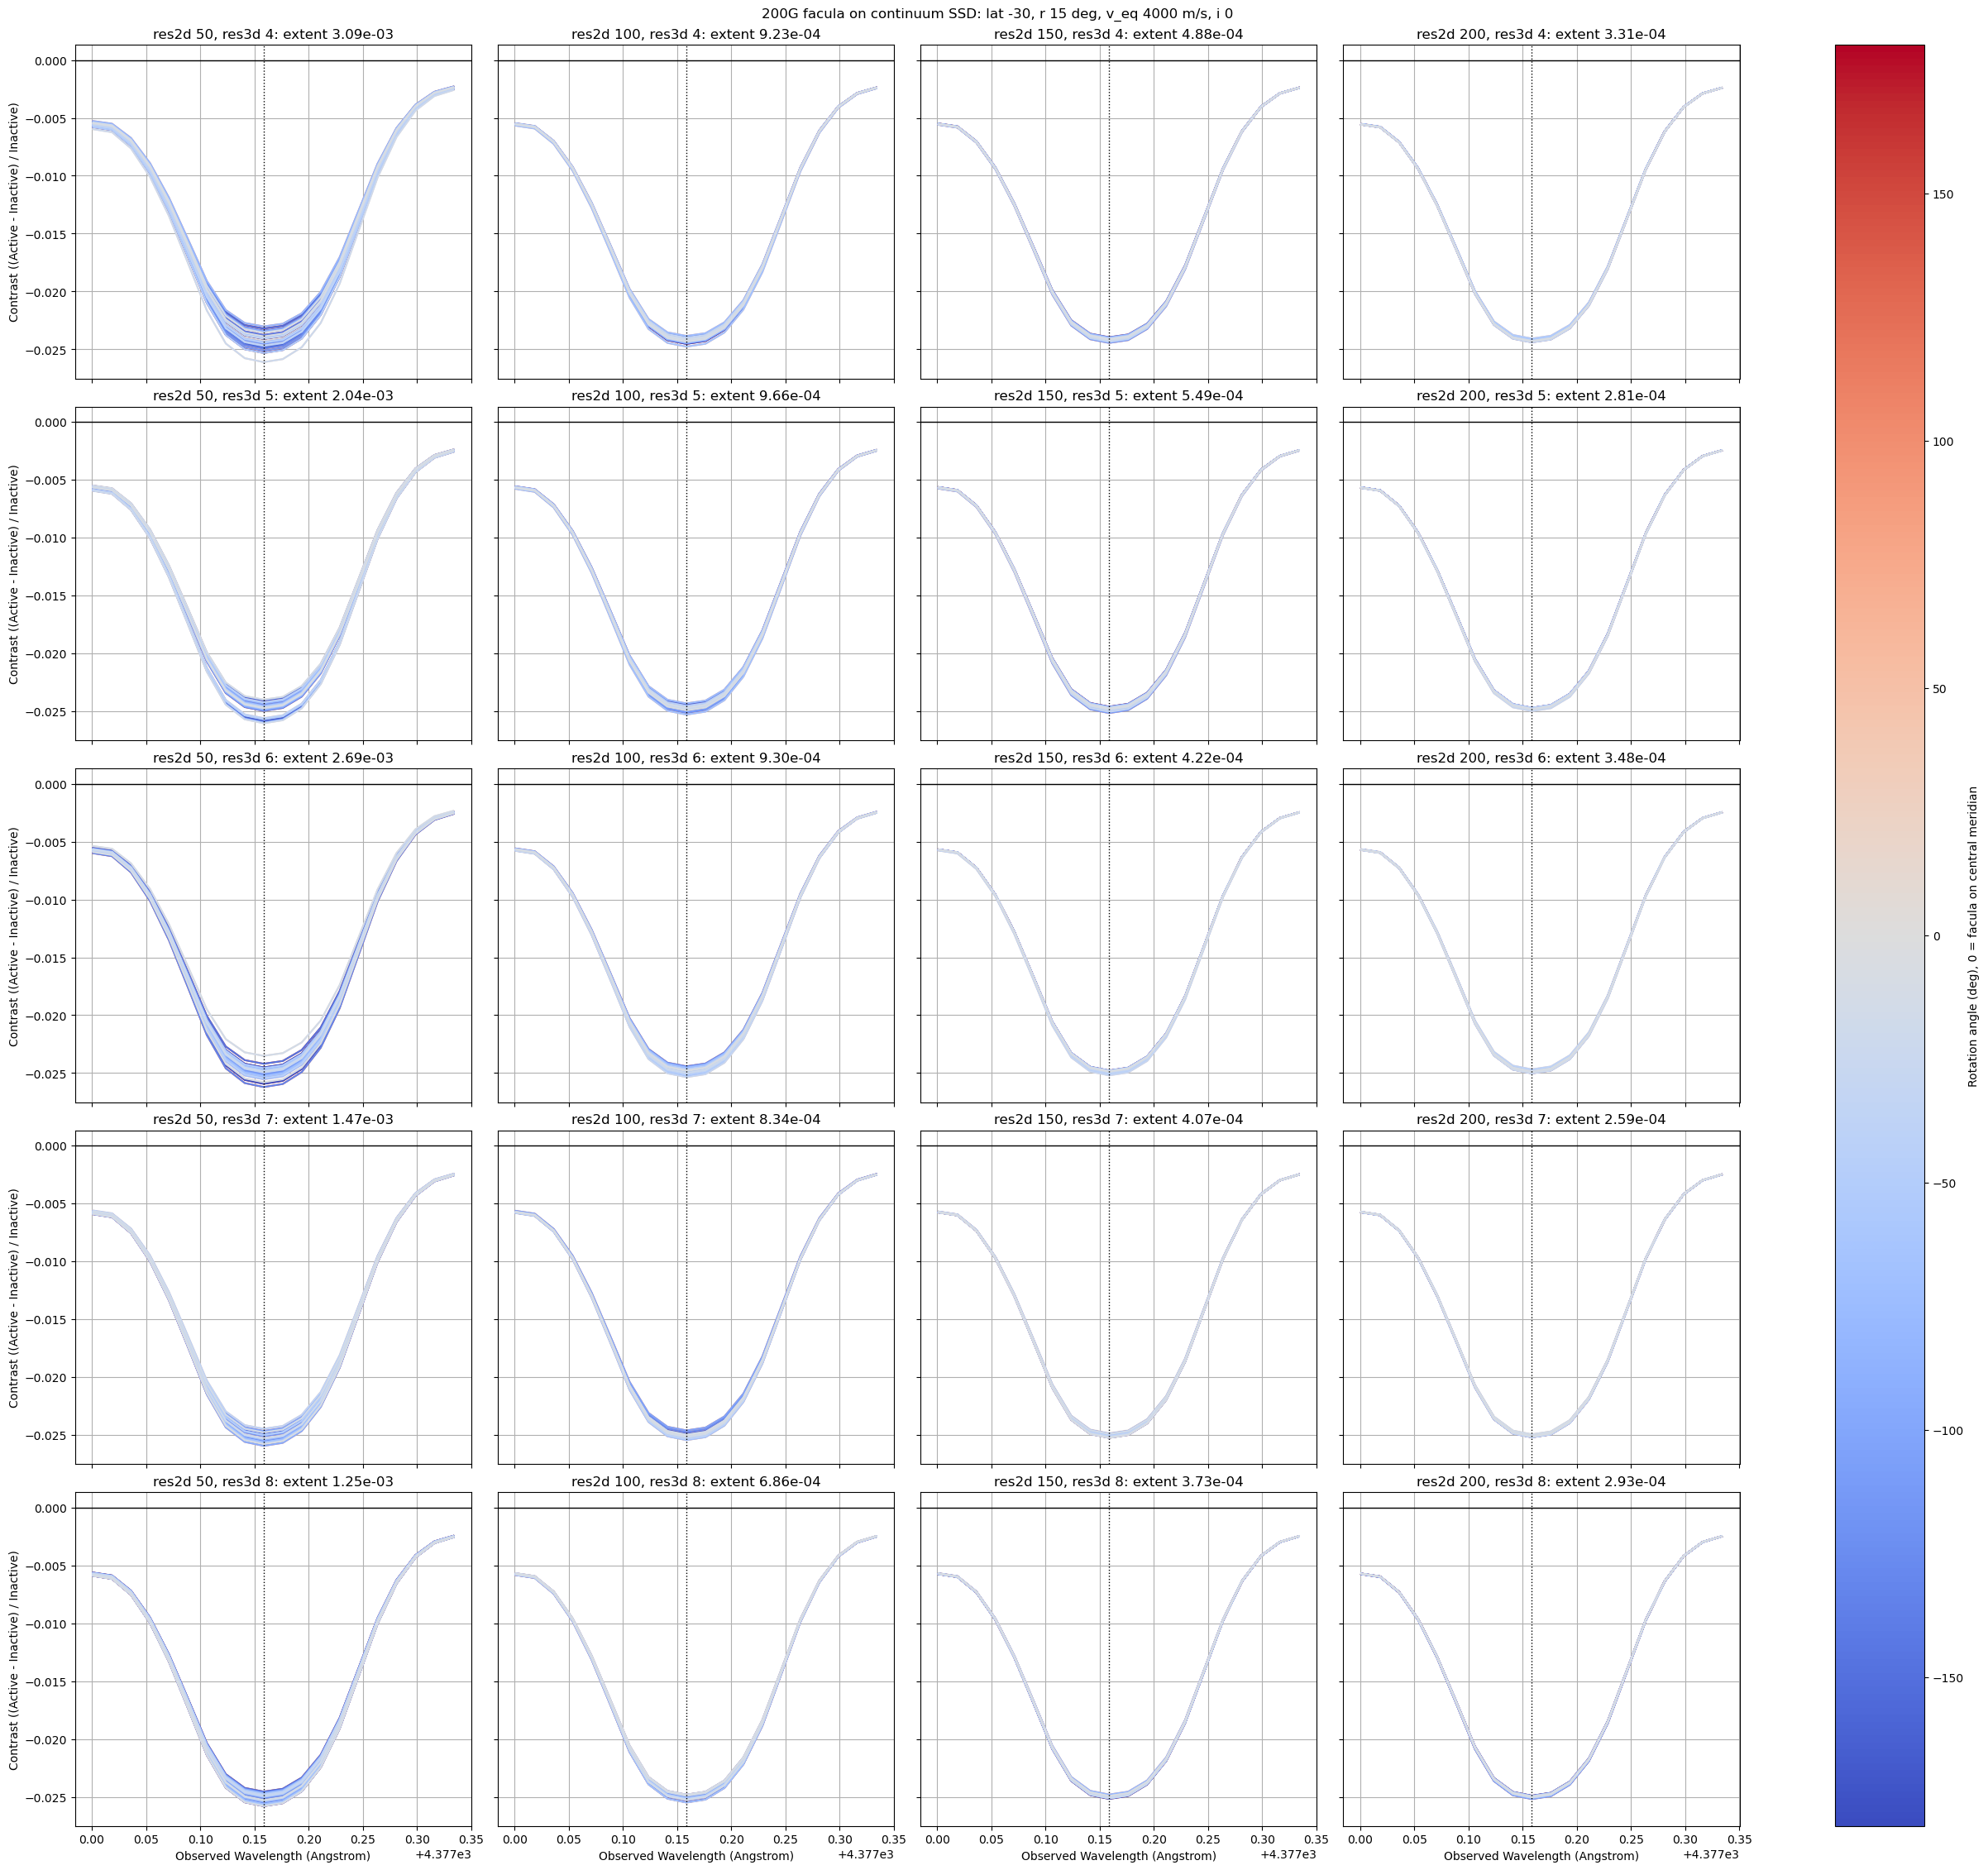

In [5]:
# ----- grid of contrast curves: rows res3d, columns res2d -----
# Signed angle (-180 to 180) so the two limbs get distinct colours; 0 = central meridian.
signed_angles = (rotation_angles + 180) % 360 - 180
cmap = plt.get_cmap('coolwarm')
angle_norm = plt.Normalize(-180, 180)

fig, axes = plt.subplots(len(res3d_values), len(res2d_values), figsize=(6 * len(res2d_values), 4.5 * len(res3d_values)),
                         sharex=True, sharey=True, squeeze=False, constrained_layout=True)
for row, res3d in enumerate(res3d_values):
    for col, res2d in enumerate(res2d_values):
        ax = axes[row, col]
        res = results[(res2d, res3d)]
        for phase_idx in range(n_phases):
            ax.plot(res['window_wavelengths'], res['window_contrast'][phase_idx],
                    color=cmap(angle_norm(signed_angles[phase_idx])), linewidth=1.5)
        ax.axvline(res['core_wavelength'], color='k', linestyle=':', linewidth=1)   # bin the extent is measured in
        ax.axhline(0, color='k', linewidth=1)
        ax.set_title(f'res2d {res2d}, res3d {res3d}: extent {res["extent"]:.2e}')
        ax.grid(True)
    axes[row, 0].set_ylabel('Contrast ((Active - Inactive) / Inactive)')
for col in range(len(res2d_values)):
    axes[-1, col].set_xlabel('Observed Wavelength (Angstrom)')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=angle_norm)
fig.colorbar(sm, ax=axes.ravel().tolist(), label='Rotation angle (deg), 0 = facula on central meridian')
fig.suptitle(f'200G facula on continuum SSD: lat {fac_lat}, r {fac_r} deg, v_eq {v_eq} m/s, i {inc}')
plt.show()

Smallest extent 2.585e-04 at res2d 200, res3d 7


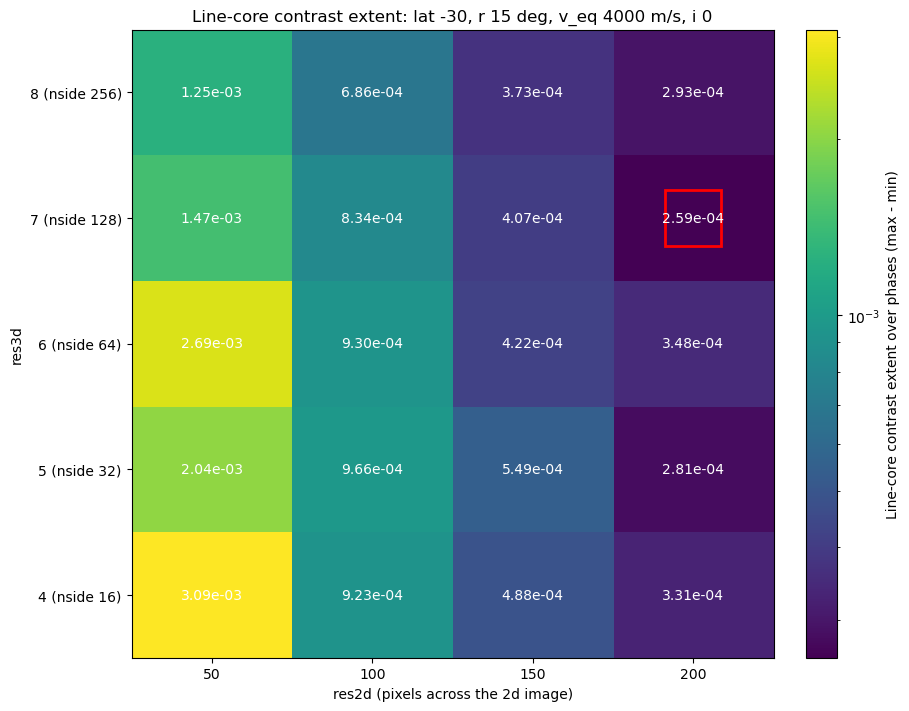

In [6]:
# ----- extent at the line core over res2d x res3d -----
extent_grid = np.zeros((len(res3d_values), len(res2d_values)))
for row, res3d in enumerate(res3d_values):
    for col, res2d in enumerate(res2d_values):
        extent_grid[row, col] = results[(res2d, res3d)]['extent']

if not np.all(np.isfinite(extent_grid)):
    raise ValueError(f"Non-finite extent in the grid:\n{extent_grid}")

# Log colour scale, as the extent can change by orders of magnitude with resolution. It cannot show
# an extent of exactly 0, so fall back to a linear scale (and say so) if one occurs.
if np.any(extent_grid <= 0):
    print("NOTE: an extent is exactly 0, so the colour scale is linear rather than log")
    extent_norm = plt.Normalize(0, extent_grid.max())
else:
    extent_norm = LogNorm(extent_grid.min(), extent_grid.max())

best_row, best_col = np.unravel_index(np.argmin(extent_grid), extent_grid.shape)
print(f"Smallest extent {extent_grid[best_row, best_col]:.3e} at res2d {res2d_values[best_col]}, res3d {res3d_values[best_row]}")

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
im = ax.imshow(extent_grid, cmap='viridis', norm=extent_norm, origin='lower', aspect='auto')
for row in range(len(res3d_values)):
    for col in range(len(res2d_values)):
        ax.text(col, row, f'{extent_grid[row, col]:.2e}', ha='center', va='center', color='w')
ax.plot(best_col, best_row, marker='s', markersize=40, markerfacecolor='none', markeredgecolor='r', markeredgewidth=2)
ax.set_xticks(range(len(res2d_values)))
ax.set_xticklabels(res2d_values)
ax.set_yticks(range(len(res3d_values)))
ax.set_yticklabels([f'{res3d} (nside {2**res3d})' for res3d in res3d_values])
ax.set_xlabel('res2d (pixels across the 2d image)')
ax.set_ylabel('res3d')
fig.colorbar(im, ax=ax, label='Line-core contrast extent over phases (max - min)')
ax.set_title(f'Line-core contrast extent: lat {fac_lat}, r {fac_r} deg, v_eq {v_eq} m/s, i {inc}')
plt.show()

res2d parity 2 centres nearest disk centre (R)   outermost (R)  spacing (R)
   50   even        -0.02041         0.02041  -1.000   1.000      0.04082
   51    odd         0.00000         0.04000  -1.000   1.000      0.04000
  100   even        -0.01010         0.01010  -1.000   1.000      0.02020
  101    odd         0.00000         0.02000  -1.000   1.000      0.02000
  150   even        -0.00671         0.00671  -1.000   1.000      0.01342
  151    odd         0.00000         0.01333  -1.000   1.000      0.01333
  200   even        -0.00503         0.00503  -1.000   1.000      0.01005
  201    odd         0.00000         0.01000  -1.000   1.000      0.01000


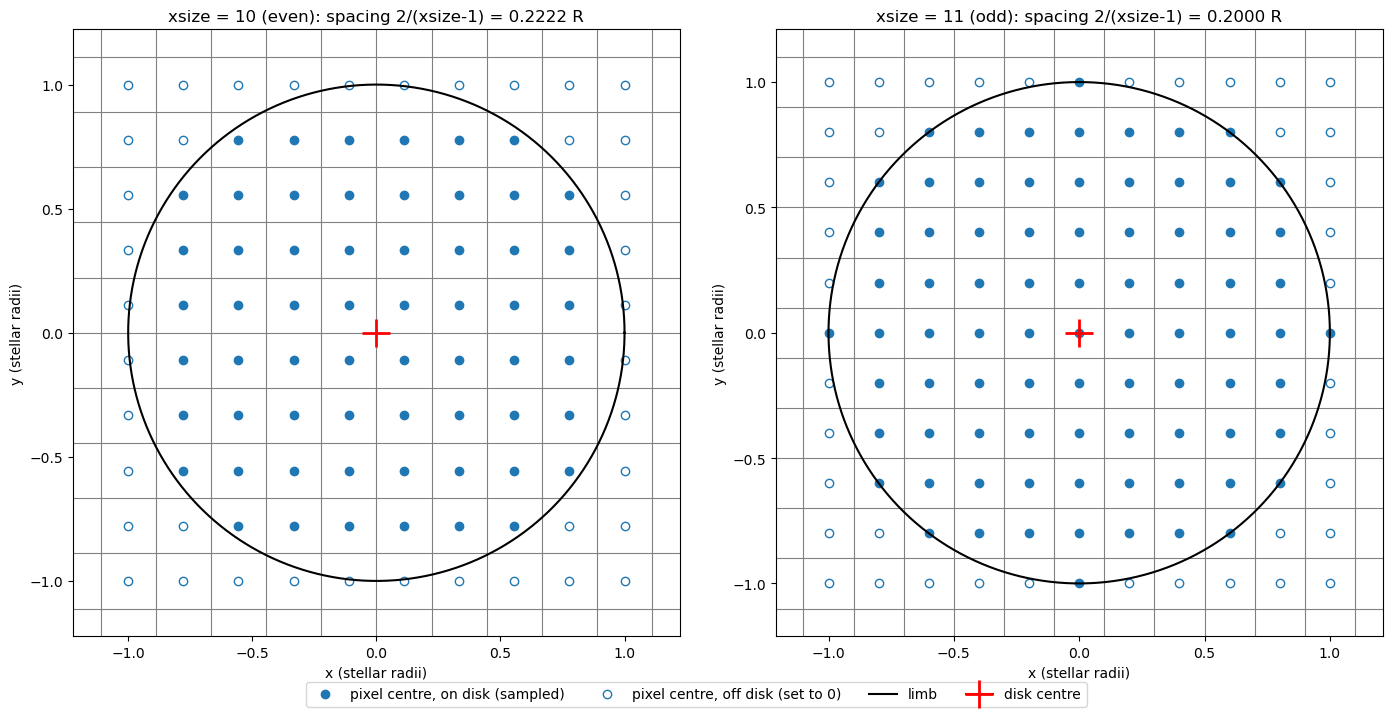

In [7]:
# ----- where the 2d pixel centres fall: even vs odd res2d -----
# simulator.rotate_lc projects with hp.projector.OrthographicProj(..., half_sky=True, xsize=res2d).projmap,
# which gives each image pixel the value of the single healpix cell under the pixel centre (no area averaging).
# The centres come from OrthographicProj.ij2xy: x = (idx - xc) / xc with xc = (xsize - 1) / 2, in stellar radii.
# So the outermost centres sit exactly on the limb (x = -1, +1), the spacing is 2 / (xsize - 1), and only an
# odd xsize puts a centre on the disk centre. Uses the healpy projector itself, not a re-derivation.
import healpy as hp

def pixel_centres(xsize):
    """x centres of one image row (stellar radii) and the on-disk mask, from the projector simulator.rotate_lc uses."""
    x, y = hp.projector.OrthographicProj(rot=[0, -90], half_sky=True, xsize=xsize).ij2xy()
    x_centres = np.asarray(x.data[0])
    y_centres = np.asarray(y.data[:, 0])
    on_disk = ~np.ma.getmaskarray(x)   # ij2xy masks x^2 + y^2 > 1, so centres exactly on the limb are kept
    return x_centres, y_centres, on_disk

print(f"{'res2d':>5} {'parity':>6} {'2 centres nearest disk centre (R)':>32} {'outermost (R)':>15} {'spacing (R)':>12}")
for res2d in res2d_values:
    for xsize in (res2d, res2d + 1):
        x_centres, _, _ = pixel_centres(xsize)
        nearest = np.sort(x_centres[np.argsort(np.abs(x_centres))[:2]])
        parity = 'even' if xsize % 2 == 0 else 'odd'
        print(f"{xsize:5d} {parity:>6} {nearest[0]:15.5f} {nearest[1]:15.5f} {x_centres[0]:7.3f} {x_centres[-1]:7.3f} {x_centres[1] - x_centres[0]:12.5f}")

# Small grids so individual pixels are visible; the geometry is the same at the sweep's res2d.
demo_xsizes = [10, 11]
fig, axes = plt.subplots(1, len(demo_xsizes), figsize=(7 * len(demo_xsizes), 7), constrained_layout=True)
limb_angle = np.linspace(0, 2 * np.pi, 400)
for ax, xsize in zip(axes, demo_xsizes):
    x_centres, y_centres, on_disk = pixel_centres(xsize)
    spacing = x_centres[1] - x_centres[0]   # stellar radii
    # Pixel boundaries: each pixel is its centre +- spacing / 2, so the outer pixels extend half a pixel past the limb.
    boundaries = np.append(x_centres - spacing / 2, x_centres[-1] + spacing / 2)
    for edge in boundaries:
        ax.axvline(edge, color='grey', linewidth=0.8)
        ax.axhline(edge, color='grey', linewidth=0.8)
    x_grid, y_grid = np.meshgrid(x_centres, y_centres)
    ax.plot(x_grid[on_disk], y_grid[on_disk], linestyle='none', marker='o', color='C0', markersize=6, label='pixel centre, on disk (sampled)')
    ax.plot(x_grid[~on_disk], y_grid[~on_disk], linestyle='none', marker='o', markerfacecolor='none', color='C0', markersize=6, label='pixel centre, off disk (set to 0)')
    ax.plot(np.cos(limb_angle), np.sin(limb_angle), color='k', linewidth=1.5, label='limb')
    ax.plot(0, 0, marker='+', color='r', markersize=20, markeredgewidth=2, label='disk centre')
    parity = 'even' if xsize % 2 == 0 else 'odd'
    ax.set_title(f'xsize = {xsize} ({parity}): spacing 2/(xsize-1) = {spacing:.4f} R')
    ax.set_xlabel('x (stellar radii)')
    ax.set_ylabel('y (stellar radii)')
    ax.set_aspect('equal')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=len(labels))
plt.show()